In [1]:
import pandas as pd
import matplotlib.pyplot as plt
df=pd.read_csv("results_v2_final.csv")

In [17]:
#total number of rounds
len(df)
date_range =df['timestamp'].max()-df['timestamp'].min()
print(date_range)
print("first time stamp: ",df['timestamp'].min())
print("last time stamp: ",df['timestamp'].max())
df.groupby('resolver').size()      


1 days 05:34:49.291646
first time stamp:  2026-10-17 16:32:29.355504
last time stamp:  2026-10-18 22:07:18.647150


resolver
cloudflare    9372
google        9372
quad9         9372
dtype: int64

In [18]:
df["round"] = df["timestamp"].dt.floor("h")
per_round = df.groupby("round").agg(rows=("success", "size"), ok=("success", "mean"))
per_round.head(20)

,rows,ok
round,,
2026-10-17 16:00:00,3408,1.000000
2026-10-17 17:00:00,1704,0.999413
2026-10-17 18:00:00,1704,1.000000
2026-10-17 19:00:00,1704,0.999413
2026-10-17 20:00:00,1704,0.999413
2026-10-17 21:00:00,1704,1.000000
2026-10-17 22:00:00,1704,1.000000
2026-10-17 23:00:00,1704,1.000000
2026-10-18 00:00:00,1704,1.000000


In [20]:
df.groupby('resolver')['success'].value_counts()

resolver    success
cloudflare  True       9372
google      True       9372
quad9       True       9366
            False         6
Name: count, dtype: int64

In [ ]:
df.groupby(["resolver","transport"])["latency_ms"].describe(percentiles=[.5,.95,.99])


count        mean         std      min       50%  \
resolver   transport                                                      
cloudflare doh        4686.0   29.606934   73.018258   7.5408  14.35055   
           udp        4686.0   19.789870   32.989480   1.9377   6.82530   
google     doh        4686.0   49.150894   55.056677   8.1211  36.33670   
           udp        4686.0   21.283330   35.073317   1.4961   6.83455   
quad9      doh        4680.0  109.968390  254.797534  37.4036  65.28790   
           udp        4686.0   21.405589   34.780531   1.4648   6.95230   

                             95%         99%        max  
resolver   transport                                     
cloudflare doh         74.932775  234.891190  1857.2100  
           udp         92.337575  149.235405   613.6797  
google     doh        141.655250  208.332615  2154.6423  
           udp         98.822850  168.256260   395.7697  
quad9      doh        219.590150  764.955127  4859.9529  
           udp         97.362450  182.821335   377.7286

In [23]:
df.groupby(["resolver","transport"])["latency_ms"].median()
df.groupby(["resolver","transport"])["latency_ms"].quantile(0.95)


resolver    transport
cloudflare  doh           74.932775
            udp           92.337575
google      doh          141.655250
            udp           98.822850
quad9       doh          219.590150
            udp           97.362450
Name: latency_ms, dtype: float64

In [24]:
df.groupby(["resolver","transport"])["latency_ms"].quantile(0.95)

resolver    transport
cloudflare  doh           74.932775
            udp           92.337575
google      doh          141.655250
            udp           98.822850
quad9       doh          219.590150
            udp           97.362450
Name: latency_ms, dtype: float64

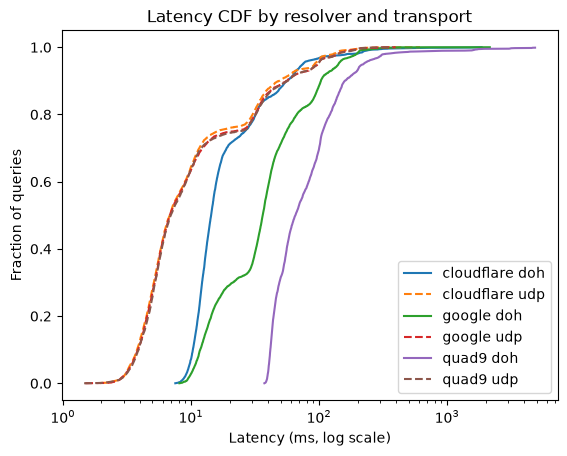

In [26]:
import numpy as np
import matplotlib.pyplot as plt

for (resolver, transport), g in df.groupby(["resolver", "transport"]):
    x = np.sort(g["latency_ms"])
    y = np.arange(1, len(x) + 1) / len(x)
    style = "-" if transport == "doh" else "--"
    plt.plot(x, y, linestyle=style, label=f"{resolver} {transport}")

plt.xscale("log")
plt.xlabel("Latency (ms, log scale)")
plt.ylabel("Fraction of queries")
plt.title("Latency CDF by resolver and transport")
plt.legend()
plt.savefig("cdf.png", dpi=200, bbox_inches="tight")
plt.show()

In [27]:
from scipy.stats import wilcoxon

def paired_tests(data):
    p = data.pivot_table(index=["round", "website"],
                         columns="resolver",
                         values="latency_ms").dropna()
    print("paired rows:", len(p))
    for a, b in [("cloudflare", "google"),
                 ("google", "quad9"),
                 ("cloudflare", "quad9")]:
        stat, pval = wilcoxon(p[a], p[b])
        diff = (p[a] - p[b]).median()
        print(f"{a} vs {b}: median diff = {diff:.2f} ms, p = {pval:.3g}")

print("DoH")
paired_tests(df[df["transport"] == "doh"])

print("UDP")
paired_tests(df[df["transport"] == "udp"])

DoH
paired rows: 2555
cloudflare vs google: median diff = -17.56 ms, p = 2.74e-217
google vs quad9: median diff = -32.38 ms, p = 1.52e-230
cloudflare vs quad9: median diff = -50.75 ms, p = 0
UDP
paired rows: 2556
cloudflare vs google: median diff = -0.15 ms, p = 0.106
google vs quad9: median diff = -0.03 ms, p = 0.8
cloudflare vs quad9: median diff = -0.07 ms, p = 0.0719


hence from the given results we came to a cnclusion that th eresolver 1.1.1.1 is the most reliable compared to the other two by just a few numbers 

transport        doh      udp  doh_extra
resolver                                
cloudflare  14.35055  6.82530    7.52525
google      36.33670  6.83455   29.50215
quad9       65.28790  6.95230   58.33560


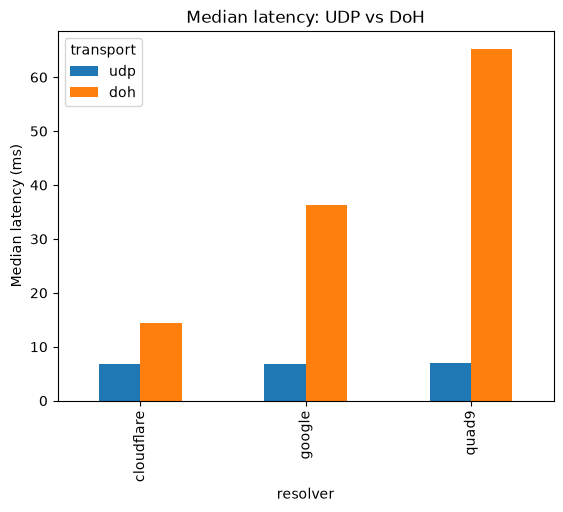

resolver
cloudflare     6.75230
google        18.38575
quad9         51.11895
Name: extra, dtype: float64


In [30]:
m = df.groupby(["resolver", "transport"])["latency_ms"].median().unstack()
m["doh_extra"] = m["doh"] - m["udp"]
print(m)

m[["udp", "doh"]].plot(kind="bar")
plt.ylabel("Median latency (ms)")
plt.title("Median latency: UDP vs DoH")
plt.savefig("median_bar.png", dpi=200, bbox_inches="tight")
plt.show()

d = df.pivot_table(index=["round", "website", "resolver"],
                      columns="transport", values="latency_ms").dropna()
d["extra"] = d["doh"] - d["udp"]
print(d.groupby("resolver")["extra"].median())

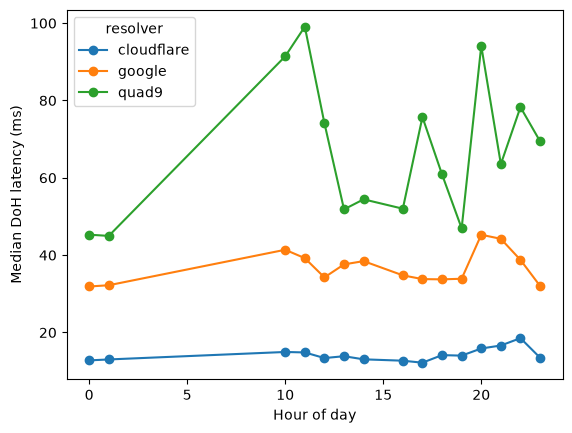

In [31]:
df["hour"] = df["timestamp"].dt.hour
hourly = (df[df["transport"] == "doh"]
          .groupby(["hour", "resolver"])["latency_ms"].median().unstack())
hourly.plot(marker="o")
plt.xlabel("Hour of day")
plt.ylabel("Median DoH latency (ms)")
plt.savefig("hourly.png", dpi=200, bbox_inches="tight")
plt.show()

group
International    14652
Indian           13464
Name: count, dtype: int64
resolver       cloudflare    google    quad9
group                                       
Indian           15.68190  41.15970  91.4606
International    13.27035  32.61905  55.0680


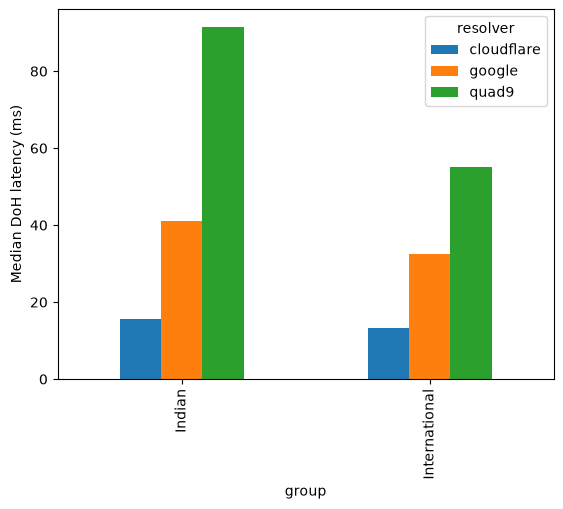

In [32]:
import numpy as np

indian_list = ["flipkart.com","amazon.in","myntra.com","meesho.com","nykaa.com","ajio.com","snapdeal.com","bigbasket.com","blinkit.com","jiomart.com","zomato.com","swiggy.com","irctc.co.in","makemytrip.com","goibibo.com","redbus.in","cleartrip.com","easemytrip.com","olacabs.com","paytm.com","phonepe.com","razorpay.com","npci.org.in","sbi.co.in","hdfcbank.com","icicibank.com","axisbank.com","kotak.com","zerodha.com","groww.in","upstox.com","moneycontrol.com","hotstar.com","jiosaavn.com","gaana.com","sonyliv.com","zee5.com","bookmyshow.com","cricbuzz.com","espncricinfo.com","ndtv.com","hindustantimes.com","indianexpress.com","thehindu.com","news18.com","indiatoday.in","livemint.com","indiatimes.com","naukri.com","justdial.com","practo.com","jio.com","airtel.in","india.gov.in","incometax.gov.in","uidai.gov.in","digilocker.gov.in","isro.gov.in","iitb.ac.in","vit.ac.in","nic.in","mygov.in","rbi.org.in","sebi.gov.in","iitm.ac.in","tcs.com","infosys.com","bsnl.co.in"]

df["group"] = np.where(df["website"].isin(indian_list),
                          "Indian", "International")
print(df["group"].value_counts())

g = (df[df["transport"] == "doh"]
     .groupby(["group", "resolver"])["latency_ms"].median().unstack())
print(g)
g.plot(kind="bar")
plt.ylabel("Median DoH latency (ms)")
plt.savefig("india_vs_intl.png", dpi=200, bbox_inches="tight")
plt.show()

In [33]:
p95 = df.groupby(["resolver", "transport"])["latency_ms"].transform(
    lambda s: s.quantile(0.95))
slow = df[df["latency_ms"] > p95]

print(slow.groupby("round").size().sort_values().tail(10))
print(slow.groupby("website").size().sort_values().tail(10))

round
2026-10-18 22:00:00     52
2026-10-17 20:30:00     55
2026-10-18 12:00:00     56
2026-10-17 22:00:00     57
2026-10-18 11:00:00     59
2026-10-17 21:00:00     66
2026-10-18 10:30:00     67
2026-10-18 11:30:00     81
2026-10-17 16:30:00    108
2026-10-18 20:00:00    151
dtype: int64
website
iitm.ac.in            33
gaana.com             34
justdial.com          34
zee5.com              34
indiatimes.com        35
hindustantimes.com    38
news18.com            38
livemint.com          41
isro.gov.in           41
f5.com                67
dtype: int64


In [34]:
raw = df[df["success"]]
print("raw median:\n", raw.groupby(["resolver", "transport"])["latency_ms"].median())
print("clean median:\n", df.groupby(["resolver", "transport"])["latency_ms"].median())

raw median:
 resolver    transport
cloudflare  doh          14.35055
            udp           6.82530
google      doh          36.33670
            udp           6.83455
quad9       doh          65.28790
            udp           6.95230
Name: latency_ms, dtype: float64
clean median:
 resolver    transport
cloudflare  doh          14.35055
            udp           6.82530
google      doh          36.33670
            udp           6.83455
quad9       doh          65.28790
            udp           6.95230
Name: latency_ms, dtype: float64
